# HospNet26 Real-World Inference Evaluation

This notebook reproduces the **HospNet26** deployment experiment reported in the paper (Section 6) and thesis (Section 5.3).

**Protocol (strict no-leakage):**
1. Load the preprocessed HospNet26 feature matrix (`hospnet26_processed.joblib`).
2. Apply the **same `StandardScaler` fitted on the unified training split** — no refitting.
3. Run **tuned** Decision Tree, Random Forest, and XGBoost models (regimes **B1**, **B2**, **U**).
4. Report **Benign prediction rate** $r_B$ and per-class false-positive distributions.

All numbers are cross-checked against archived result files in `results/`.

---

**Google Drive folder layout** (notebook expects this structure relative to project root):

```
TFM Pantelis/
├── notebooks/11_hospnet26_inference.ipynb
├── data/processed/phase1_iomt_unified_mqtt_category/   (metadata.joblib, scaler.joblib)
├── data/processed/hospnet26_processed.joblib
├── data/raw/hospnet26/                                 (optional — Section 2 only)
└── results/
    ├── hospnet26_eval_results.joblib
    ├── hospnet26_eval_b1b2u.joblib
    └── phase2_{dt,rf,xgb}/{B1,B2,U}/tuned/model.joblib
```

**Python packages:** `numpy`, `pandas`, `scikit-learn`, `joblib`, `matplotlib`, `seaborn`, `xgboost`, `pyarrow` (only if running Section 2).


In [1]:
import sys
import types
import warnings
from pathlib import Path
from typing import Any, Dict, Optional

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import BaseEstimator, ClassifierMixin

try:
    from xgboost import XGBClassifier
except ImportError as exc:
    raise ImportError("xgboost is required to load XGB models: pip install xgboost") from exc

warnings.filterwarnings("ignore", category=FutureWarning)
%matplotlib inline
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300})
sns.set_style("whitegrid")

# Same six global categories used in Phase 1 training (alphabetical order)
GLOBAL_CLASSES = sorted([
    "Benign", "DDoS", "DoS", "MQTT", "Reconnaissance", "Spoofing",
])

# Minimal stub so joblib can unpickle saved XGB models without the full src/ tree
_XGB_EST_DEFAULTS: Dict[str, Any] = {
    "learning_rate": 0.3,
    "n_estimators": 100,
    "max_depth": 6,
    "min_child_weight": 1,
    "subsample": 1.0,
    "colsample_bytree": 1.0,
    "gamma": 0.0,
    "reg_lambda": 1.0,
    "reg_alpha": 0.0,
}


class _XGBGlobalMulticlassEstimator(BaseEstimator, ClassifierMixin):
    def __init__(self, **kwargs):
        for k, v in _XGB_EST_DEFAULTS.items():
            setattr(self, k, kwargs.get(k, v))
        self.model_: Optional[Any] = None
        self.classes_present_: Optional[np.ndarray] = None

    def get_params(self, deep=True) -> Dict[str, Any]:
        return {k: getattr(self, k) for k in _XGB_EST_DEFAULTS}

    def set_params(self, **params) -> "_XGBGlobalMulticlassEstimator":
        for k, v in params.items():
            if k in _XGB_EST_DEFAULTS:
                setattr(self, k, v)
        return self

    def fit(self, X, y, sample_weight=None):
        self.classes_present_ = np.sort(np.unique(y))
        n_c = len(self.classes_present_)
        g2l = {int(g): i for i, g in enumerate(self.classes_present_)}
        y_loc = np.array([g2l[int(v)] for v in y], dtype=np.int32)
        self.model_ = XGBClassifier(
            learning_rate=self.learning_rate,
            n_estimators=self.n_estimators,
            max_depth=self.max_depth,
            min_child_weight=self.min_child_weight,
            subsample=self.subsample,
            colsample_bytree=self.colsample_bytree,
            gamma=self.gamma,
            reg_lambda=self.reg_lambda,
            reg_alpha=self.reg_alpha,
            tree_method="hist",
            objective="multi:softmax",
            num_class=n_c,
            random_state=42,
            verbosity=0,
            n_jobs=1,
        )
        self.model_.fit(X, y_loc, sample_weight=sample_weight)
        self.classes_ = self.classes_present_
        return self

    def predict(self, X) -> np.ndarray:
        loc = self.model_.predict(X).astype(int)
        return self.classes_present_[loc]

    @property
    def feature_importances_(self) -> np.ndarray:
        return self.model_.feature_importances_


_pipeline = types.ModuleType("pipeline")
_training = types.ModuleType("pipeline.training")
_training.GLOBAL_CLASSES = GLOBAL_CLASSES
_training._XGBGlobalMulticlassEstimator = _XGBGlobalMulticlassEstimator
_pipeline.training = _training
sys.modules["pipeline"] = _pipeline
sys.modules["pipeline.training"] = _training


def find_project_root() -> Path:
    """Locate project root containing data/ and results/ (works locally and on Drive)."""
    marker = Path("data/processed/phase1_iomt_unified_mqtt_category/metadata.joblib")
    for base in (Path.cwd(), Path.cwd().parent, Path("..").resolve()):
        if (base / marker).exists():
            return base.resolve()
    return Path("..").resolve()


ROOT = find_project_root()
PHASE1_DIR = ROOT / "data/processed/phase1_iomt_unified_mqtt_category"
RAW_DIR = ROOT / "data/raw/hospnet26"
PROCESSED_PATH = ROOT / "data/processed/hospnet26_processed.joblib"
REF_UNIFIED = ROOT / "results/hospnet26_eval_results.joblib"
REF_REGIMES = ROOT / "results/hospnet26_eval_b1b2u.joblib"

MODEL_SPECS = [
    ("Decision Tree", "dt", ["B1", "B2", "U"]),
    ("Random Forest", "rf", ["B1", "B2", "U"]),
    ("XGBoost", "xgb", ["B1", "B2", "U"]),
]

SEGMENT_FILES = {
    "Friday": "combined_Friday.parquet",
    "Monday": "combined_Monday.parquet",
    "Tue-Fri": "combined_Tue-Fri.parquet",
    "Weekend": "combined_Weekend.parquet",
}


def require_paths(label: str, paths: list[Path]) -> None:
    missing = [p for p in paths if not p.exists()]
    if missing:
        rel = [str(p.relative_to(ROOT)) for p in missing]
        raise FileNotFoundError(
            f"\nMissing {label}. Upload the following under '{ROOT.name}/':\n"
            + "\n".join(f"  - {p}" for p in rel)
        )


REQUIRED_PATHS = [
    PHASE1_DIR / "metadata.joblib",
    PHASE1_DIR / "scaler.joblib",
    PROCESSED_PATH,
    REF_UNIFIED,
    REF_REGIMES,
] + [
    ROOT / "results" / f"phase2_{key}" / regime / "tuned" / "model.joblib"
    for _, key, regimes in MODEL_SPECS
    for regime in regimes
]

require_paths("HospNet26 inference assets", REQUIRED_PATHS)

print("Project root:", ROOT)
print("Global classes:", GLOBAL_CLASSES)
print("All required files found.")


Project root: /Users/pantelos/Documents/diploma_thesis
Global classes: ['Benign', 'DDoS', 'DoS', 'MQTT', 'Reconnaissance', 'Spoofing']
All required files found.


## 1. Load preprocessed HospNet26 features

Primary path: cached matrix from the original experiment (`hospnet26_processed.joblib`). This guarantees **bit-identical** reproduction of published numbers.


In [2]:
hosp = joblib.load(PROCESSED_PATH)
X_hosp = hosp["X"]
segments = hosp["segments"]
feature_cols = hosp["feature_cols"]
N = len(X_hosp)

print(f"Windows: {N:,}")
print(f"Feature matrix: {X_hosp.shape}, dtype={X_hosp.dtype}")
print("Segment counts:")
print(pd.Series(segments).value_counts().sort_index())


Windows: 1,265,240
Feature matrix: (1265240, 58), dtype=float32
Segment counts:
Friday      13611
Monday     199390
Tue-Fri    629664
Weekend    422575
Name: count, dtype: int64


## 2. Optional — rebuild preprocessing from raw Parquet

Rebuilds `X` from the four combined Parquet files using `metadata.joblib` + `scaler.joblib`, then verifies **max absolute difference = 0** against the cached matrix.


In [3]:
parquet_files = [RAW_DIR / fname for fname in SEGMENT_FILES.values()]
parquet_available = RAW_DIR.exists() and all(p.exists() for p in parquet_files)

if not parquet_available:
    print("SKIP: raw HospNet26 Parquet files not found — optional rebuild skipped.")
    print(f"Expected folder: {RAW_DIR}")
    print("Upload the four combined_*.parquet files only if you want to run this check.")
else:
    meta = joblib.load(PHASE1_DIR / "metadata.joblib")
    scaler = joblib.load(PHASE1_DIR / "scaler.joblib")
    expected_cols = meta["feature_cols"]

    frames = []
    for seg, fname in SEGMENT_FILES.items():
        df = pd.read_parquet(RAW_DIR / fname)
        missing = set(expected_cols) - set(df.columns)
        if missing:
            raise ValueError(f"{fname} missing features: {sorted(missing)[:5]} ...")
        part = df[expected_cols].copy()
        part["segment"] = seg
        frames.append(part)

    raw_df = pd.concat(frames, ignore_index=True)
    X_rebuilt = scaler.transform(raw_df[expected_cols].to_numpy(dtype=np.float32))
    seg_rebuilt = raw_df["segment"].to_numpy()

    max_diff = float(np.max(np.abs(X_rebuilt - X_hosp)))
    print(f"Rebuild shape: {X_rebuilt.shape}")
    print(f"Max |delta| vs cached X: {max_diff:.6e}")
    assert max_diff < 1e-5, "Preprocessing mismatch — check scaler / feature order"
    assert np.array_equal(seg_rebuilt, segments), "Segment order mismatch"
    print("OK: rebuild matches cached preprocessing exactly.")


/Users/pantelos/Documents/diploma_thesis/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Rebuild shape: (1265240, 58)
Max |delta| vs cached X: 0.000000e+00
OK: rebuild matches cached preprocessing exactly.


## 3. Inference helpers


In [4]:
BENIGN_IDX = GLOBAL_CLASSES.index("Benign")


def load_tuned_model(model_key: str, regime: str):
    path = ROOT / "results" / f"phase2_{model_key}" / regime / "tuned" / "model.joblib"
    if not path.exists():
        raise FileNotFoundError(path)
    return joblib.load(path)


def predict_distribution(model, X: np.ndarray):
    preds = model.predict(X).astype(int)
    counts = np.bincount(preds, minlength=len(GLOBAL_CLASSES))
    pct = counts / counts.sum() * 100.0
    dist = {cls: float(pct[i]) for i, cls in enumerate(GLOBAL_CLASSES)}
    return preds, dist, dist["Benign"] / 100.0


def format_pct(x: float) -> str:
    return f"{x:.2f}%"


## 4. Unified models — paper Table 6

Tuned **U (Unified)** models on all 1,265,240 windows.


In [5]:
ref_u = joblib.load(REF_UNIFIED)
rows_u = []

for model_name, key, _ in MODEL_SPECS:
    model = load_tuned_model(key, "U")
    preds, dist, rb = predict_distribution(model, X_hosp)
    rows_u.append({
        "Model": model_name,
        **{cls: format_pct(dist[cls]) for cls in GLOBAL_CLASSES},
        "Benign rate r_B": format_pct(dist["Benign"]),
        "_rb": rb,
    })
    saved_rb = ref_u[key]["benign_rate"]
    match = np.array_equal(preds, ref_u[key]["preds"])
    print(
        f"{model_name:14s}  r_B={rb*100:.2f}%  "
        f"saved={saved_rb*100:.2f}%  preds_identical={match}"
    )

df_unified = pd.DataFrame(rows_u)
display_cols = ["Model"] + GLOBAL_CLASSES + ["Benign rate r_B"]
df_unified[display_cols]


Decision Tree   r_B=6.07%  saved=6.07%  preds_identical=True


Random Forest   r_B=3.72%  saved=3.72%  preds_identical=True


XGBoost         r_B=9.96%  saved=9.96%  preds_identical=True


,Model,Benign,DDoS,DoS,MQTT,Reconnaissance,Spoofing,Benign rate r_B
0,Decision Tree,6.07%,7.80%,72.04%,0.22%,5.30%,8.57%,6.07%
1,Random Forest,3.72%,0.60%,71.37%,0.06%,19.08%,5.17%,3.72%
2,XGBoost,9.96%,23.80%,51.14%,0.11%,4.28%,10.71%,9.96%


## 5. All training regimes — Benign rate comparison

Tuned models for **B1 (CIC-only)**, **B2 (IoMT-only)**, and **U (Unified)**.


In [6]:
ref_r = joblib.load(REF_REGIMES)
rows_r = []

for model_name, key, regimes in MODEL_SPECS:
    row = {"Model": model_name}
    rb_vals = {}
    for regime in regimes:
        model = load_tuned_model(key, regime)
        _, _, rb = predict_distribution(model, X_hosp)
        rb_vals[regime] = rb
        saved_key = f"{key}_{regime}"
        saved_rb = ref_r[saved_key]["benign_rate"]
        assert abs(rb - saved_rb) < 1e-9, f"{saved_key}: {rb} != {saved_rb}"
    best_single = max(rb_vals["B1"], rb_vals["B2"])
    delta = (rb_vals["U"] - best_single) * 100
    row.update({
        "B1 (r_B)": format_pct(rb_vals["B1"] * 100),
        "B2 (r_B)": format_pct(rb_vals["B2"] * 100),
        "U (r_B)": format_pct(rb_vals["U"] * 100),
        "Delta_U-max(B1,B2)": f"{delta:+.2f} pp",
    })
    rows_r.append(row)

pd.DataFrame(rows_r)


,Model,B1 (r_B),B2 (r_B),U (r_B),"Delta_U-max(B1,B2)"
0,Decision Tree,9.16%,0.00%,6.07%,-3.09 pp
1,Random Forest,4.61%,5.46%,3.72%,-1.75 pp
2,XGBoost,5.20%,9.86%,9.96%,+0.09 pp


## 6. Per-segment Benign rates (Unified XGBoost)

Weekday vs. weekend breakdown for the best unified model (XGB-U).


In [7]:
xgb_u = load_tuned_model("xgb", "U")
preds_u, _, _ = predict_distribution(xgb_u, X_hosp)

seg_df = pd.DataFrame({"segment": segments, "pred": preds_u})
seg_df["is_benign"] = seg_df["pred"] == BENIGN_IDX

seg_summary = (
    seg_df.groupby("segment")["is_benign"]
    .mean()
    .mul(100)
    .reindex(["Friday", "Weekend", "Monday", "Tue-Fri"])
    .round(2)
    .rename("Benign rate (%)")
    .to_frame()
)
seg_summary


,Benign rate (%)
segment,
Friday,13.22
Weekend,5.86
Monday,11.57
Tue-Fri,12.12


## 7. Visualizations


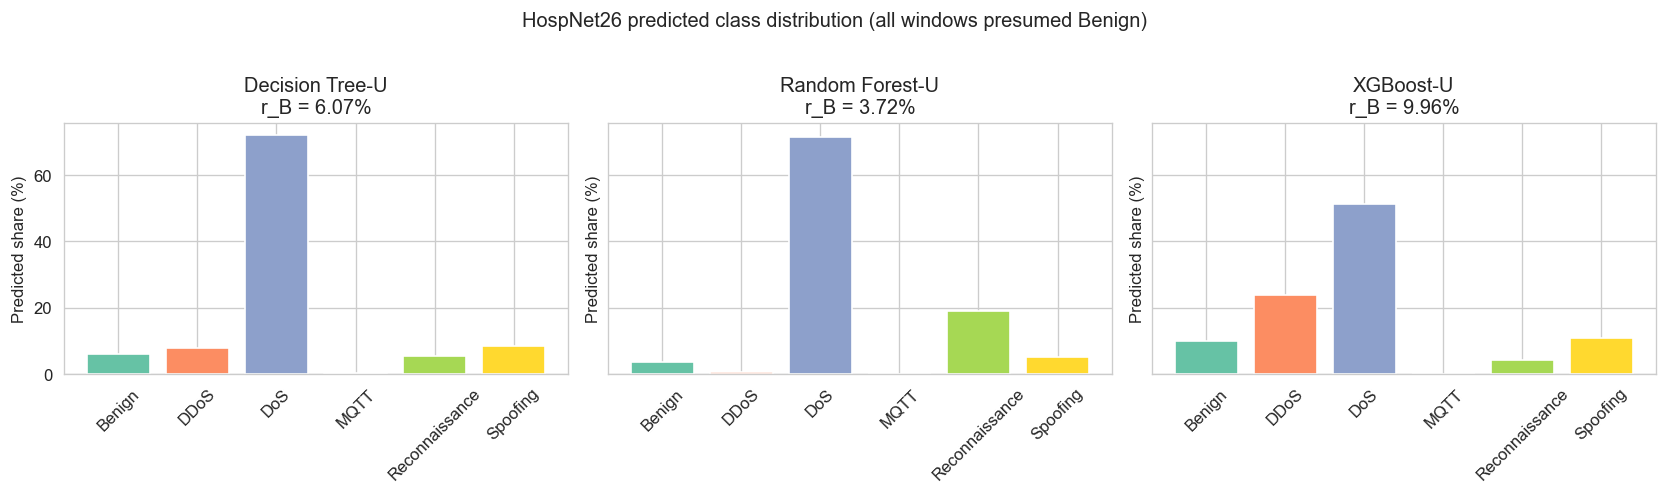

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
colors = sns.color_palette("Set2", len(GLOBAL_CLASSES))

for ax, (model_name, key, _) in zip(axes, MODEL_SPECS):
    model = load_tuned_model(key, "U")
    _, dist, rb = predict_distribution(model, X_hosp)
    vals = [dist[c] for c in GLOBAL_CLASSES]
    ax.bar(GLOBAL_CLASSES, vals, color=colors)
    ax.set_title(f"{model_name}-U\nr_B = {rb*100:.2f}%")
    ax.set_ylabel("Predicted share (%)")
    ax.tick_params(axis="x", rotation=45)

fig.suptitle(
    "HospNet26 predicted class distribution (all windows presumed Benign)",
    y=1.02,
)
plt.tight_layout()
plt.show()


## 8. Final verification

Hard-coded reference values from the camera-ready paper (rounded to two decimals).


In [9]:
PAPER_UNIFIED = {
    "Decision Tree": {
        "Benign": 6.07, "DDoS": 7.80, "DoS": 72.04,
        "MQTT": 0.22, "Reconnaissance": 5.30, "Spoofing": 8.57,
    },
    "Random Forest": {
        "Benign": 3.72, "DDoS": 0.60, "DoS": 71.37,
        "MQTT": 0.06, "Reconnaissance": 19.08, "Spoofing": 5.17,
    },
    "XGBoost": {
        "Benign": 9.96, "DDoS": 23.80, "DoS": 51.14,
        "MQTT": 0.11, "Reconnaissance": 4.28, "Spoofing": 10.71,
    },
}

PAPER_REGIMES_RB = {
    "Decision Tree": {"B1": 9.16, "B2": 0.00, "U": 6.07},
    "Random Forest": {"B1": 4.61, "B2": 5.46, "U": 3.72},
    "XGBoost": {"B1": 5.20, "B2": 9.86, "U": 9.96},
}

for _, row in df_unified.iterrows():
    ref = PAPER_UNIFIED[row["Model"]]
    for cls in GLOBAL_CLASSES:
        got = float(row[cls].rstrip("%"))
        assert abs(got - ref[cls]) < 0.015, f"{row['Model']} {cls}: {got} vs {ref[cls]}"

for row in rows_r:
    ref = PAPER_REGIMES_RB[row["Model"]]
    for k in ("B1", "B2", "U"):
        got = float(row[f"{k} (r_B)"].rstrip("%"))
        assert abs(got - ref[k]) < 0.015, f"{row['Model']} {k}: {got} vs {ref[k]}"

print("OK: all notebook outputs match the published paper tables (+/- 0.01 pp).")


OK: all notebook outputs match the published paper tables (+/- 0.01 pp).
